# Model Training

## Importing the Data Set

The code below runs the code in the previous notebook, which had all of the data preprocessing steps. This allows one to use variables and functions defined in the code of another notebook. 

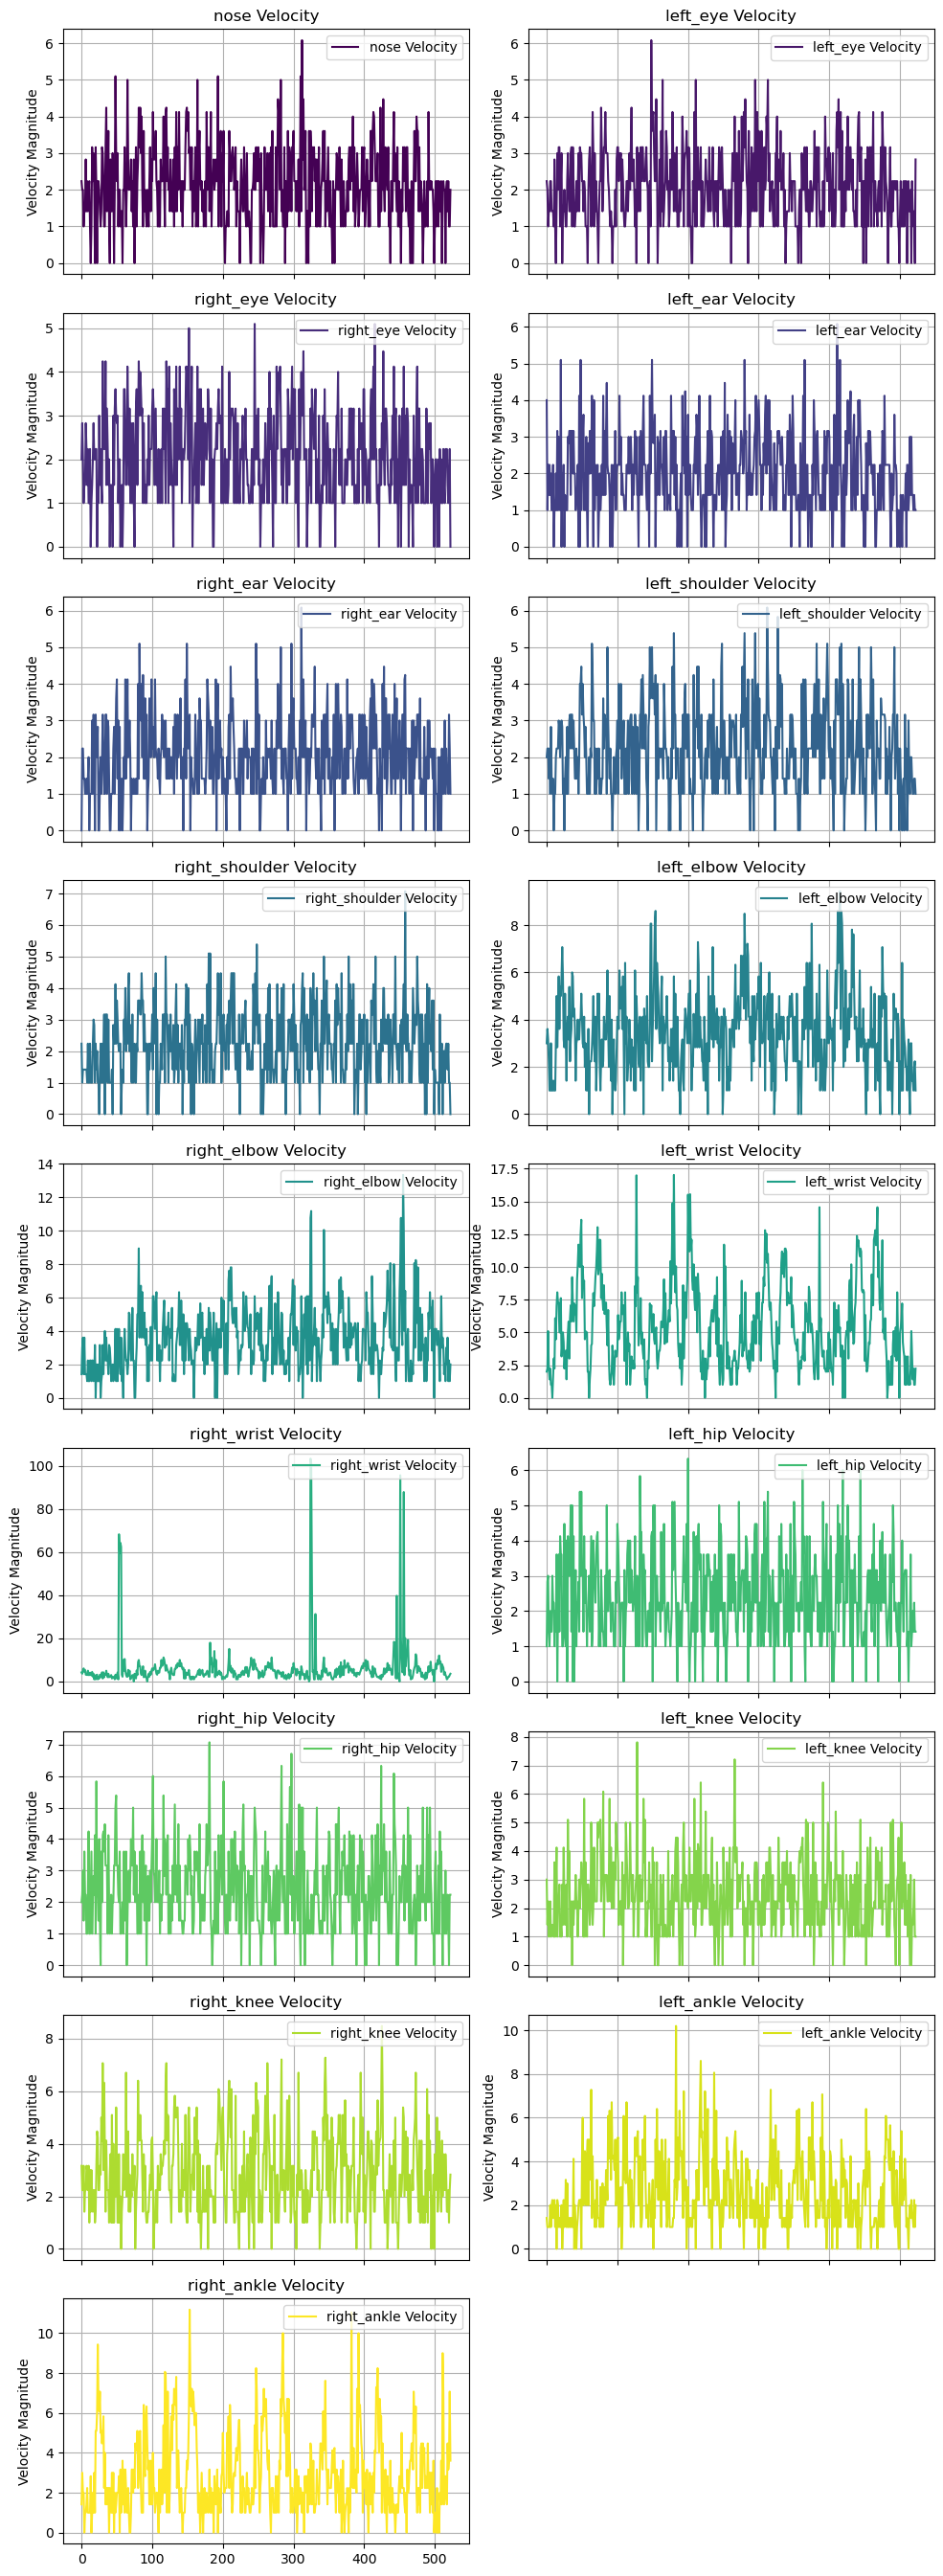

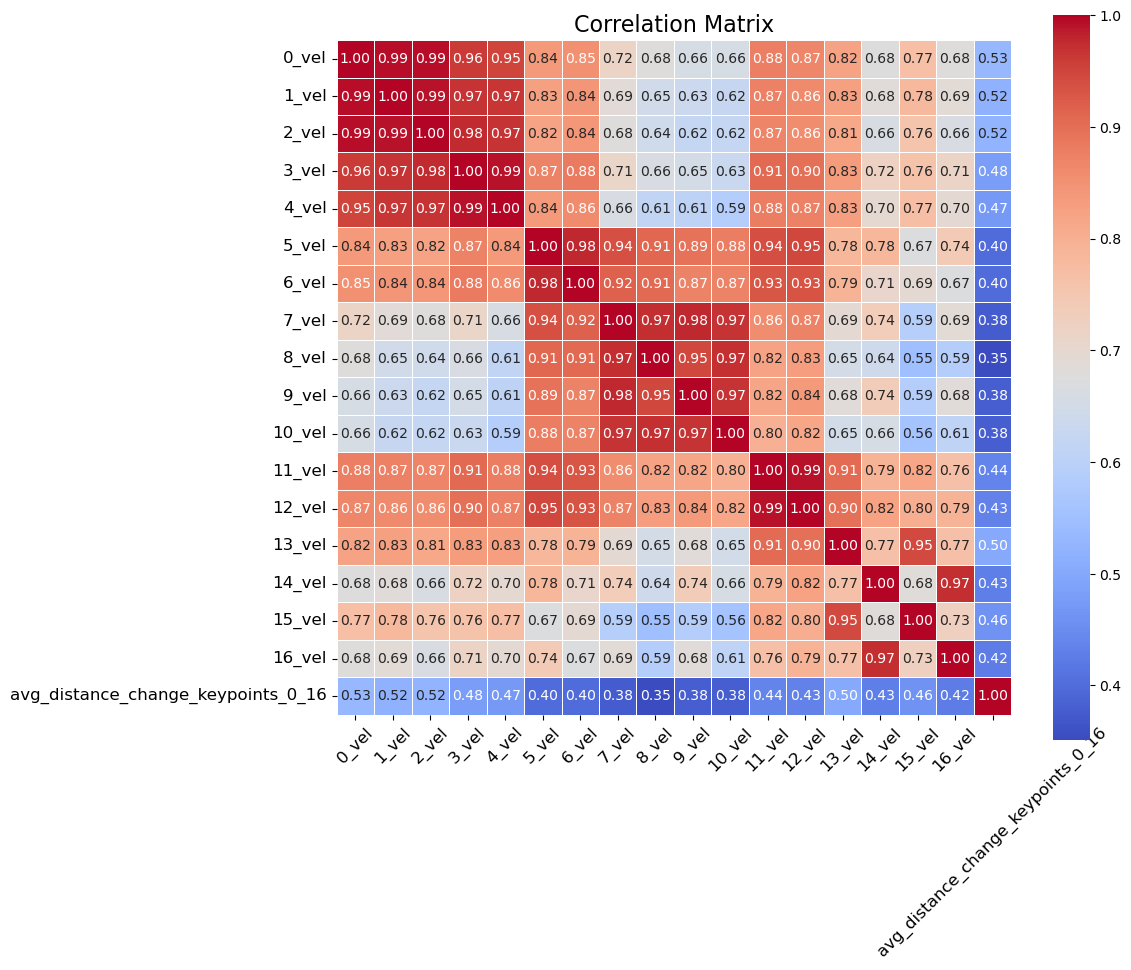

In [1]:
%run 02_data_preprocessing.ipynb

## Training the Model

The below code splits the data into training and testing sets. It also changes the labels into integers and makes sure the X data and y labels are the same length.

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split

X = df_new  # Features 
y = df['label']    

# Train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Assuming y_train and y_test are your original labels corresponding to your keypoints and timestamps
y_train_binary = (y_train == "house").astype(int)  # Binary encoding for training labels
y_test_binary = (y_test == "house").astype(int)    # Binary encoding for testing labels

# Check lengths to ensure they match
assert len(X_train) == len(y_train_binary), f"Length mismatch: {len(X_train)} vs {len(y_train)}"
assert len(X_test) == len(y_test_binary), f"Length mismatch: {len(X_test)} vs {len(y_test)}"


### Classifiers

First, without modification to the features, I will run various classifiers on the data to see which provide the most accurate results.

In [3]:
# Fit the classifier (e.g., SGDClassifier)
from sklearn.linear_model import SGDClassifier

# Initialize the classifier
SGD_clf = SGDClassifier(max_iter=1000, tol=1e-3, random_state=42)

# Fit the model
SGD_clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred_sgd = SGD_clf.predict(X_test)

In [4]:
from sklearn.linear_model import LogisticRegression

# Initialize the classifier
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# Fit the model
log_reg.fit(X_train, y_train)

# Make predictions
y_pred_log = log_reg.predict(X_test)

In [5]:
from sklearn.svm import SVC

# Initialize the classifier
svm_clf = SVC(kernel='linear', random_state=42)

# Fit the model
svm_clf.fit(X_train, y_train)

# Make predictions
y_pred_svm = svm_clf.predict(X_test)

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Initialize the classifier
knn_clf = KNeighborsClassifier(n_neighbors=5)

# Fit the model
knn_clf.fit(X_train, y_train)

# Make predictions
y_pred_knn = knn_clf.predict(X_test)

In [7]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the classifier
dt_clf = DecisionTreeClassifier(random_state=42)

# Fit the model
dt_clf.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_clf.predict(X_test)

In [8]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit the model
rf_clf.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_clf.predict(X_test)